In [73]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier


<font size = 5>1. Perform data quality check by checking for missing values if any.</font>

In [74]:
df = pd.read_excel("hr-comma-sepcsv.xlsx")

In [75]:
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [77]:
#Change average_monthly_hours to average_weekly_hours for better calculations and change name of sales column to department for better readability
df = df.rename(columns={'average_montly_hours' : 'average_weekly_hours','sales':'department'})
df['average_weekly_hours'] = df['average_weekly_hours']*12/52
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_weekly_hours   14999 non-null  float64
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(3), int64(5), object(2)
memory usage: 1.1+ MB


In [78]:
#Find correlation between no of projects and average weekly hours
print(np.corrcoef(df['number_project'],df['average_weekly_hours']))

[[1.         0.41721063]
 [0.41721063 1.        ]]


<font size=2>Correlation factor is 0.4172 which is not high so we cannot remove any one of number_project or average_weekly_hours<font>

<font size=5>2. Understand what factors contributed most to employee turnover by EDA.</font>

In [79]:
df.describe()

,satisfaction_level,last_evaluation,number_project,average_weekly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,46.396232,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,11.525331,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,22.153846,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,36.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,46.153846,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,56.538462,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,71.538462,10.000000,1.000000,1.000000,1.000000


<font size=3> We may draw the following insights from the above data:</font>

<font size=3>1. Employees are relatively short tenure with the company(as time_spend_company mean = 3.5 years and max = 10 years)</font>

<font size=3>2. Employees are generally above average performers(as the last evaluation mean is 0.71)</font>

<font size=3>3. 14.46% of employees i.e.,1 in 7 employees, had work accidents</font>

<font size=3>4. More employees are satisfied with the company(mean of satisfaction_level = 0.61)</font>

In [80]:
df.describe(include=['O'])

,department,salary
count,14999,14999
unique,10,3
top,sales,low
freq,4140,7316


In [81]:
#Pivoting pair of features
df[['Work_accident','left']].groupby(['Work_accident'],as_index = False).mean().sort_values(by='left')


,Work_accident,left
1,1,0.077916
0,0,0.265160


In [82]:
df[['department','left']].groupby(['department'],as_index = False).mean().sort_values(by = 'left',ascending = False)

,department,left
3,hr,0.290934
2,accounting,0.265971
9,technical,0.256250
8,support,0.248991
7,sales,0.244928
5,marketing,0.236597
0,IT,0.222494
6,product_mng,0.219512
1,RandD,0.153748
4,management,0.144444


In [83]:
df[['salary','left']].groupby(['salary'],as_index = False).mean().sort_values(by = 'left',ascending = False)

,salary,left
1,low,0.296884
2,medium,0.204313
0,high,0.066289


In [84]:
df[['number_project','left']].groupby(['number_project'],as_index = False).mean().sort_values(by = 'number_project')

,number_project,left
0,2,0.656198
1,3,0.017756
2,4,0.093700
3,5,0.221659
4,6,0.557922
5,7,1.000000


In [85]:
df[['time_spend_company', 'left']].groupby(['time_spend_company'], as_index=False).mean().sort_values(by='time_spend_company')

,time_spend_company,left
0,2,0.016338
1,3,0.246159
2,4,0.348064
3,5,0.565513
4,6,0.291086
5,7,0.000000
6,8,0.000000
7,10,0.000000


<font size = 3>Observations:</font>

<font size = 3>1. Having an accident at work does not necessarily correlate strongly with leaving the firm (8% of those who had accidents left while 
26% of those who did not have accidents left)</font>

<font size = 3>2. R&D and management depts seem to experience the least turnover, while the other departments have similar turnover rates.</font>

<font size = 3>3. Salary seems inversely correlated with how likely someone will leave</font>

<font size = 3>4. People tend to leave when they're on a few projects or many projects.</font>

<font size = 3>5. Workers are more likely to leave once they've spent a few years at the firm, but after 7 years everyone has stayed</font>

<font size = 3>Conclusions:<font>

<font size = 3>1. We should not consider the Work_accident feature in our model</font>

<font size = 3>2. The department feature does not seem that useful, given the similar rates between departments. However, we can leave it in for now
We should consider salary in our model<font>

<font size = 3>3. Include the number of projects feature, but consider turning it into a binary variable: "Normal" (between 3 and 5 projects, since the mean number of projects is 3.8) versus not</font>

<font size = 3>4. Include the years at the firm feature, but band years 7 and onward</font>

<font size=5>3. Perform clustering of Employees who left based on their satisfaction and evaluation.</font>

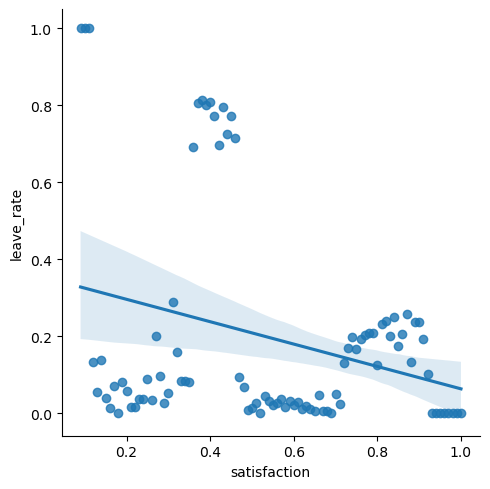

In [86]:
#calculate the "leave_rate" by for each instance of the numerical features by dividing the number of employees that left by the total.
leave_sat=df.groupby('satisfaction_level').agg({'left': lambda x: len(x[x==1])})
leave_sat['total']=df.groupby('satisfaction_level').agg({'left': len})
leave_sat['leave_rate']=leave_sat['left']/leave_sat['total']
leave_sat['satisfaction']=df.groupby('satisfaction_level').agg({'satisfaction_level': 'mean'})
g=sns.lmplot(x='satisfaction', y='leave_rate',data=leave_sat)

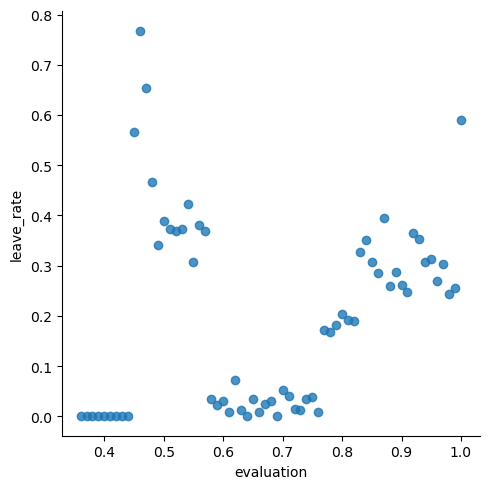

In [87]:
leave_eval=df.groupby('last_evaluation').agg({'left': lambda x: len(x[x==1])})
leave_eval['total']=df.groupby('last_evaluation').agg({'left': len})
leave_eval['leave_rate']=leave_eval['left']/leave_eval['total']
leave_eval['evaluation']=df.groupby('last_evaluation').agg({'last_evaluation': 'mean'})
gr=sns.lmplot(x='evaluation', y='leave_rate',data=leave_eval,fit_reg=False)

<font size=3>Observations:</font>

<font size=3>1. We observe that lower satisfaction levels are associated with higher levels of turnover, as expected</font>

<font size=3>2. Regarding evaluation scores, it's interesting to note the two "clusters" that form; the people who leave tend to either have received low scores (.6 and below) or very high scores (.8 and above). Employees scoring in the middle rarely left.</font>

<font size=3>Conclusions:</font>

<font size=3>1. Use the satisfaction_level feature in our model</font>

<font size=3>2. We may need to do some data wrangling on the last_evaluation feature. Consider creating two bands, exceptional scores (both really good and really bad evaluations) vs. the rest.</font>


In [88]:
#Count no of employees who got promotions
(df.promotion_last_5years==1).sum()

np.int64(319)

<font size=2>Number of promoted employees are negligible so we can drop the column promotion_last_5years</font> 

In [89]:
#Drop promotion column
df=df.drop(['promotion_last_5years'],axis=1)

<font size=5>Data Wrangling</font>


<font size=2>1. we drop the work_accident, department, and average_weekly_hours features</font>

<font size=2>2. we band the number_project, time_spend_company (years at the firm), and last_evaluation features</font>

In [90]:
df=df.drop(['Work_accident','department','average_weekly_hours'],axis=1)
df.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'time_spend_company', 'left', 'salary'],
      dtype='object')

In [91]:
#banding number of projects
bins=[0,2,5,10]
names=[1,0,1]
df['abnormal_proj']=pd.cut(df['number_project'],bins,labels=names,ordered=False)
#banding years at the firm
bins2=[0,1,2,3,4,5,6,100]
names2=['1','2','3','4','5','6','7']
df['years_at_company']=pd.cut(df['time_spend_company'],bins2,labels=names2,ordered=False)
#banding last_evaluation
bins3=[0,.6,.8,1]
names3=[1,0,1]
df['abnormal_eval']=pd.cut(df['last_evaluation'],bins3,labels=names3,ordered=False)
df.head()

,satisfaction_level,last_evaluation,number_project,time_spend_company,left,salary,abnormal_proj,years_at_company,abnormal_eval
0,0.38,0.53,2,3,1,low,1,3,1
1,0.80,0.86,5,6,1,medium,0,6,1
2,0.11,0.88,7,4,1,medium,1,4,1
3,0.72,0.87,5,5,1,low,0,5,1
4,0.37,0.52,2,3,1,low,1,3,1


In [92]:
#cleaning up intermediary/unused columns
df=df.drop(['number_project','time_spend_company','last_evaluation'],axis=1)
df.head()

,satisfaction_level,left,salary,abnormal_proj,years_at_company,abnormal_eval
0,0.38,1,low,1,3,1
1,0.80,1,medium,0,6,1
2,0.11,1,medium,1,4,1
3,0.72,1,low,0,5,1
4,0.37,1,low,1,3,1


In [93]:
#turning all columns into numeric so that modeling algorithms can run
df['salary']=df['salary'].map({'low':0,'medium':1,'high':2}).astype(int)
pd.to_numeric(df['abnormal_proj'], errors='coerce')
pd.to_numeric(df['years_at_company'], errors='coerce')
pd.to_numeric(df['abnormal_eval'], errors='coerce')
df.head()

,satisfaction_level,left,salary,abnormal_proj,years_at_company,abnormal_eval
0,0.38,1,0,1,3,1
1,0.80,1,1,0,6,1
2,0.11,1,1,1,4,1
3,0.72,1,0,0,5,1
4,0.37,1,0,1,3,1


<font size=5>5. Perform k-fold cross-validation model training and evaluate performance</font>

In [94]:
#Modeling
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(df,df['left'],test_size=.2)
X_train=X_train.drop('left',axis=1)
X_test=X_test.drop('left',axis=1)
print (X_train.shape, Y_train.shape)
print (X_test.shape, Y_test.shape)

(11999, 5) (11999,)
(3000, 5) (3000,)


<font size=5>6. Identify the best model and justify the evaluation metrics used.</font>

<font size=3>The goal of our model is to use a set of employee characteristics to label him/her as "left the firm" or "stayed". 
Essentially, we are looking for supervised learning algorithms that perform "classification" and "regression".Apply</font>

<font size=3>1. Logistic Regression</font>

<font size=3>2. KNN or k-Nearest Neighbors</font>

<font size=3>3. Support Vector Machines</font>

<font size=3>4. Naive Bayes classifier</font>

<font size=3>5. Decision Tree</font>

In [99]:
#Log reg
logreg = LogisticRegression()
logreg.fit(X_train, Y_train)
Y_train = Y_train.astype('int')
Y_test=Y_test.astype('int')
X_train = X_train.astype('int')
X_test = X_test.astype('int')
Y_pred = logreg.predict(X_test)
acc_log = round(logreg.score(X_train, Y_train) * 100, 2)
acc_log

86.0

<font size = 3>The coefficients represent the level of impact each feature has on the probability of an employee leaving. For each one-unit increase in a given feature, the log-odds are scaled by that feature's coefficient.</font>

<font size=3>Taking a look at the coefficients table, we see that working on an excessive number of projects (both too few or too many) and having a stellar/poor evaluation are correlated strongest with quitting the firm. Similarly, higher satisfaction and salary tend to significantly decrease the probability of leaving the firm.</font>

In [100]:
coeff_df = pd.DataFrame(X_train.columns)
coeff_df.columns = ['Feature']
coeff_df["Coefficient"] = pd.Series(logreg.coef_[0])

coeff_df.sort_values(by='Coefficient', ascending=False)

,Feature,Coefficient
2,abnormal_proj,2.640476
4,abnormal_eval,2.189119
3,years_at_company,0.520296
1,salary,-0.723173
0,satisfaction_level,-1.372098


In [101]:
#KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, Y_train)
Y_pred = knn.predict(X_test)
acc_knn = round(knn.score(X_train, Y_train) * 100, 2)
acc_knn

88.16

In [103]:
#SVM
svc = SVC()
svc.fit(X_train, Y_train)
Y_pred = svc.predict(X_test)
acc_svc = round(svc.score(X_train, Y_train) * 100, 2)
acc_svc

90.66

In [104]:
#NB
gaussian = GaussianNB()
gaussian.fit(X_train, Y_train)
Y_pred = gaussian.predict(X_test)
acc_gaussian = round(gaussian.score(X_train, Y_train) * 100, 2)
acc_gaussian

39.76

In [105]:
#Decision Tree
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train, Y_train)
Y_pred = decision_tree.predict(X_test)
acc_decision_tree = round(decision_tree.score(X_train, Y_train) * 100, 2)
acc_decision_tree

91.17

In [112]:
models = pd.DataFrame({
    'Model': ['Support Vector Machines', 'KNN', 'Logistic Regression', 
              'Naive Bayes', 'Decision Tree'],
    'Score': [acc_svc, acc_knn, acc_log, 
              acc_gaussian,acc_decision_tree]})
models.sort_values(by='Score', ascending=False)

,Model,Score
4,Decision Tree,91.17
0,Support Vector Machines,90.66
1,KNN,88.16
2,Logistic Regression,86.00
3,Naive Bayes,39.76


<font size=5>Model Evaluation</font>

<font size=3>We now summarize the models we used and rank them based on their accuracy. The decision trees algorithm scored the highest, predicting 91% of the test set's employees' decisions to leave.</font>